# Can an ADHD Prediction Model Work in U.S. States It Has Never Seen?
### CIS 631 Machine Learning Project – NSCH 2023–2025

**Research question.** Can a machine-learning model trained on children's data from some U.S. states predict parent-reported ADHD in children from states it has never seen?

**Data.** The National Survey of Children's Health (NSCH) asks parents about their children's health, family and daily life. We use the **Topical** survey files.
* **Target (Y):** `k2q31a` – "Has a doctor ever told you this child has ADHD?" (Yes = 1, No = 0).
* **Groups:** `fipsst` – the child's state. States are **geographic sites, not hospitals**. We use the state only to split the data, never as a model input.

**What we compare.**
* Two feature sets: 17 family and lifestyle features, and 27 features (the 17 plus 10 behaviour and health features).
* Six models: linear regression, logistic regression, decision tree, random forest, SVM and gradient boosting.
* Four ways of splitting the data: random, a geographic split, Group K-Fold by state, and leave-one-state-out.

*Note:* the label is a parent's report, not a doctor's diagnosis, so this model is not a medical tool.

**How this improves on our previous ADHD-200 work.** ADHD-200 had about 973 children from 9 research sites, with brain scans and only a few phenotypic variables. NSCH 2023–2025 has about 103,000 school-age children from all 51 state-level areas, and many more survey variables. That gives us more data, more "sites" to test on, and more models to compare. The trade-off is that NSCH diagnoses are reported by parents.

*A more detailed version of this analysis, with extra experiments, is saved as `ADHD_Cross_State_Generalization_Research_full_analysis.ipynb`.*

## 1. Setup

Import the libraries we use (pandas for tables, scikit-learn for machine learning, SHAP for explanations), fix the random seed so results are the same every run, and set the data and output folders.

In [1]:
import glob, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import (train_test_split, GroupShuffleSplit, LeaveOneGroupOut,
                                     StratifiedKFold, GroupKFold, GridSearchCV, cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)
import joblib

try:
    import shap
except ImportError:                       # install SHAP the first time if it is missing
    get_ipython().run_line_magic("pip", "install -q shap")
    import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42                                 # same random seed everywhere -> same results every run

DATA_DIR = next(Path("data").glob("NSCH*"))              # data/NSCH 2023–2025
OUT = Path("output") / "nsch_project"; FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Data folder:", DATA_DIR)

Data folder: data/NSCH 2023–2025


## 2. Load the Data

**What are we doing?** We find the NSCH Stata files, load the **Topical** files and stack the survey years into one table.

**Why?** Only Topical files contain the ADHD question. The 2023 file we received is a **Screener** file (household screening only), so we must not mix it in.

In [2]:
frames = []
for path in sorted(glob.glob(str(DATA_DIR / "**" / "*.dta"), recursive=True)):
    if "topical" not in path.lower():
        print("Skipped (not a Topical file):", Path(path).name)
        continue
    df = pd.read_stata(path, convert_categoricals=False)   # keep the numeric survey codes
    df.columns = df.columns.str.lower()
    print(f"Loaded {Path(path).name}: {df.shape[0]:,} rows, {df.shape[1]} columns")
    frames.append(df)

data = pd.concat(frames, ignore_index=True)
data["survey_year"] = data["year"].astype(int)
print("\nCombined data:", data.shape, "| years:", sorted(data.survey_year.unique().tolist()))

Loaded nsch_2023e_topical.dta: 55,162 rows, 456 columns


Loaded nsch_2024e_topical.dta: 51,375 rows, 457 columns
Loaded nsch_2025e_topical.dta: 45,139 rows, 458 columns



Combined data: (151676, 464) | years: [2023, 2024, 2025]


**What did we find?** All three Topical files load correctly: 2023 (55,162 children), 2024 (51,375) and 2025 (45,139), for **151,676** children in total. The three years use the same questions and answer codes for our features. Reported ADHD was slightly lower in 2023 (15.9 % of school-age children) than in 2024–2025 (17.4 %).

Load the official NSCH descriptions and answer codes for every variable, so tables can show what each code means.

In [3]:
# Official NSCH variable descriptions and answer codes (taken from the NSCH .do files)
labels = json.loads(Path("reference/nsch_topical_labels.json").read_text())["years"]["2025"]
DESC, CODES = labels["descriptions"], labels["codes"]

## 3. Choose the Target, Features and Children

**What are we doing?** We define the target, the two feature sets and the group of children we study (ages 6–17).

**Why?** Many features (school, homework, behaviour) are only asked for school-age children, and ADHD is rarely diagnosed before age 6.

In [4]:
TARGET, STATE = "k2q31a", "fipsst"

FEATURES_17 = ["sc_age_years", "sc_sex", "family_r", "totkids_r", "a1_grade", "a1_employed_r", "a1_menthealth",
               "ace1", "ace3", "ace8", "foodsit", "bedtime", "hoursleep", "screentime", "physactiv", "k8q11", "birthwt"]
EXTRA_10 = ["k7q70_r", "k7q83_r", "k7q84_r", "k7q85_r", "k7q04r_r", "grades", "k2q33a", "k2q32a", "k2q30a", "k2q35a"]
FEATURES_27 = FEATURES_17 + EXTRA_10
FEATURE_SETS = {"17 features": FEATURES_17, "27 features": FEATURES_27}

FAIRNESS_ONLY = ["sc_race_r", "sc_hispanic_r"]      # NOT model inputs – only used to check fairness
NOT_USED = ["currins", "k2q31b", "k2q31c", "k2q31d", "addtreat"]   # insurance + ADHD current/severity/medication/treatment
print(len(FEATURES_17), "baseline features,", len(FEATURES_27), "expanded features")

17 baseline features, 27 expanded features


**Excluded on purpose:**
* **Race, ethnicity and insurance:** left out of the model inputs, so the model cannot use group membership. Race and ethnicity are kept aside only for a fairness check.
* **ADHD "current", severity, medication and treatment** (`k2q31b`, `k2q31c`, `k2q31d`, `addtreat`): these only exist because of the diagnosis. Using them would be **data leakage**, meaning the answer hidden inside the inputs.

Keep only children aged 6–17 with a Yes/No ADHD answer, create the 0/1 target column `adhd`, and convert the state code to its two-letter abbreviation.

In [5]:
kids = data[(data.sc_age_years >= 6) & (data[TARGET].isin([1, 2]))].copy()   # ages 6-17 with a Yes/No answer
kids["adhd"] = (kids[TARGET] == 1).astype(int)                                  # 1 = ADHD reported, 0 = not
FIPS_TO_STATE = {1:"AL",2:"AK",4:"AZ",5:"AR",6:"CA",8:"CO",9:"CT",10:"DE",11:"DC",12:"FL",13:"GA",15:"HI",16:"ID",17:"IL",18:"IN",
                 19:"IA",20:"KS",21:"KY",22:"LA",23:"ME",24:"MD",25:"MA",26:"MI",27:"MN",28:"MS",29:"MO",30:"MT",31:"NE",32:"NV",
                 33:"NH",34:"NJ",35:"NM",36:"NY",37:"NC",38:"ND",39:"OH",40:"OK",41:"OR",42:"PA",44:"RI",45:"SC",46:"SD",47:"TN",
                 48:"TX",49:"UT",50:"VT",51:"VA",53:"WA",54:"WV",55:"WI",56:"WY"}
kids["state"] = kids[STATE].map(FIPS_TO_STATE)                                   # state abbreviation, e.g. 6 -> "CA"
kids = kids[FEATURES_27 + FAIRNESS_ONLY + ["adhd", "state", "survey_year", "fwc"]].reset_index(drop=True)
print("Children in the study:", len(kids))

Children in the study: 103353


### 3.1 Check the features against the NSCH codebook

Build a small table with each feature's official description, a few of its answer codes, its percentage of missing answers, and the feature set it belongs to.

In [6]:
check = pd.DataFrame({
    "description": [DESC.get(c, "") for c in FEATURES_27],
    "answer codes": [", ".join(f"{k}={v[:18]}" for k, v in list(CODES.get(c, {}).items())[:4] if not k.startswith(".")) for c in FEATURES_27],
    "% missing": kids[FEATURES_27].isna().mean().mul(100).round(1).values,
    "set": ["17 + 27" if c in FEATURES_17 else "27 only" for c in FEATURES_27]}, index=FEATURES_27)
check

,description,answer codes,% missing,set
sc_age_years,Age of Selected Child - In Years,,0.0,17 + 27
sc_sex,Sex of Selected Child,"1=Male, 2=Female",0.0,17 + 27
family_r,Family Structure,"1=Two biogical/adopt, 2=Two biogical/adopt, 3=...",2.6,17 + 27
totkids_r,Number of Children in Household,"1=1, 2=2, 3=3, 4=4+",0.0,17 + 27
a1_grade,Adult 1 - Highest Completed Year of School,"1=8th grade or less, 2=9th-12th grade; No, 3=H...",0.0,17 + 27
a1_employed_r,Adult 1 - Current Employment Status,"1=Employed full-time, 2=Employed part-time, 3=...",3.7,17 + 27
a1_menthealth,Adult 1 - Mental or Emotional Health,"1=Excellent, 2=Very Good, 3=Good, 4=Fair",3.2,17 + 27
ace1,Hard to Cover Basics Like Food or Housing,"1=Never, 2=Rarely, 3=Somewhat often, 4=Very often",1.7,17 + 27
ace3,Child Experienced - Parent or Guardian Divorced,"1=Yes, 2=No",3.5,17 + 27
ace8,Child Experienced - Lived with Mentally Ill,"1=Yes, 2=No",3.9,17 + 27


**What did we find?** Every feature matches the official NSCH description, uses the same codes in both years, and has at most about 4 % missing answers. Except for age, the answers are **codes**, not measurements. For example, `hoursleep = 4` means "8 hours", and `k7q84_r = 1` means the child "always" finishes tasks. So we treat them as categories.

**Possible "after-diagnosis" information.** Several of the 10 extra features (behaviour, homework, grades, school contacts, other diagnoses) can be **caused by or recorded after** an ADHD diagnosis. That is not leakage in the strict sense, but it means the 27-feature model partly *recognises* children who already have ADHD rather than predicting it early. We keep this in mind when we interpret the results.

## 4. Explore the Data

**What are we doing?** Look at the first rows, the size, missing values, the ADHD counts, the states and the age distribution.

**Why?** We need to understand the data before training models.

In [7]:
print("Rows and columns:", kids.shape)
kids.head()

Rows and columns: (103353, 33)


,sc_age_years,sc_sex,family_r,totkids_r,a1_grade,a1_employed_r,a1_menthealth,ace1,ace3,ace8,...,k2q33a,k2q32a,k2q30a,k2q35a,sc_race_r,sc_hispanic_r,adhd,state,survey_year,fwc
0,11,1,5.0,1,5,1.0,3.0,3.0,1.0,2.0,...,2.0,2.0,2.0,2.0,2,2,0,CA,2023,1318.476840
1,14,2,1.0,2,8,1.0,1.0,2.0,2.0,2.0,...,2.0,2.0,2.0,2.0,1,1,0,CA,2023,978.499881
2,17,2,1.0,1,3,2.0,3.0,1.0,2.0,2.0,...,2.0,2.0,NaN,2.0,1,1,0,CA,2023,904.191765
3,12,2,1.0,2,6,1.0,1.0,1.0,2.0,2.0,...,2.0,2.0,2.0,2.0,1,1,0,CA,2023,1092.097256
4,10,2,2.0,2,4,5.0,3.0,1.0,2.0,2.0,...,2.0,2.0,2.0,2.0,4,2,0,CA,2023,586.387870


Two charts: the percentage of missing answers per feature, and how many children do and do not have ADHD reported.

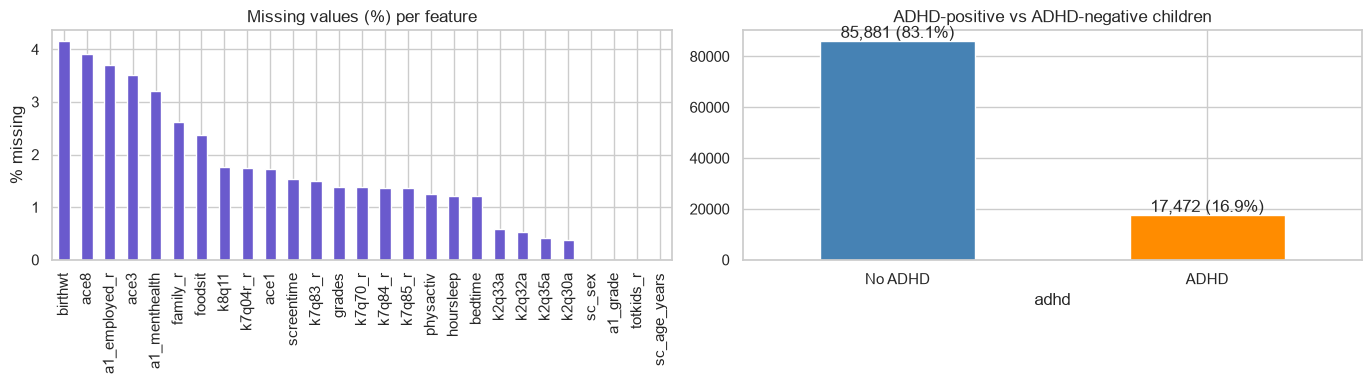

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
missing = kids[FEATURES_27].isna().mean().mul(100).sort_values(ascending=False)
missing.plot.bar(ax=axes[0], color="slateblue"); axes[0].set_title("Missing values (%) per feature"); axes[0].set_ylabel("% missing")
counts = kids.adhd.value_counts().rename({0: "No ADHD", 1: "ADHD"})
counts.plot.bar(ax=axes[1], color=["steelblue", "darkorange"], rot=0); axes[1].set_title("ADHD-positive vs ADHD-negative children")
for i, v in enumerate(counts): axes[1].text(i, v, f"{v:,} ({v / len(kids):.1%})", ha="center", va="bottom")
plt.tight_layout(); plt.savefig(FIG / "01_missing_and_classes.png", dpi=120); plt.show()

**What did we find?** Missing values are low (at most about 4 %), so we can fill them in instead of deleting children. Of the **103,353** school-age children, about **17 %** have ADHD reported, so the classes are **imbalanced**. A model that always says "No ADHD" would already be about 83 % accurate, which is why we focus on recall and F1 instead of accuracy.

Count the children in each state and the percentage with ADHD reported, and compare the raw sample percentage with the survey-weighted estimate.

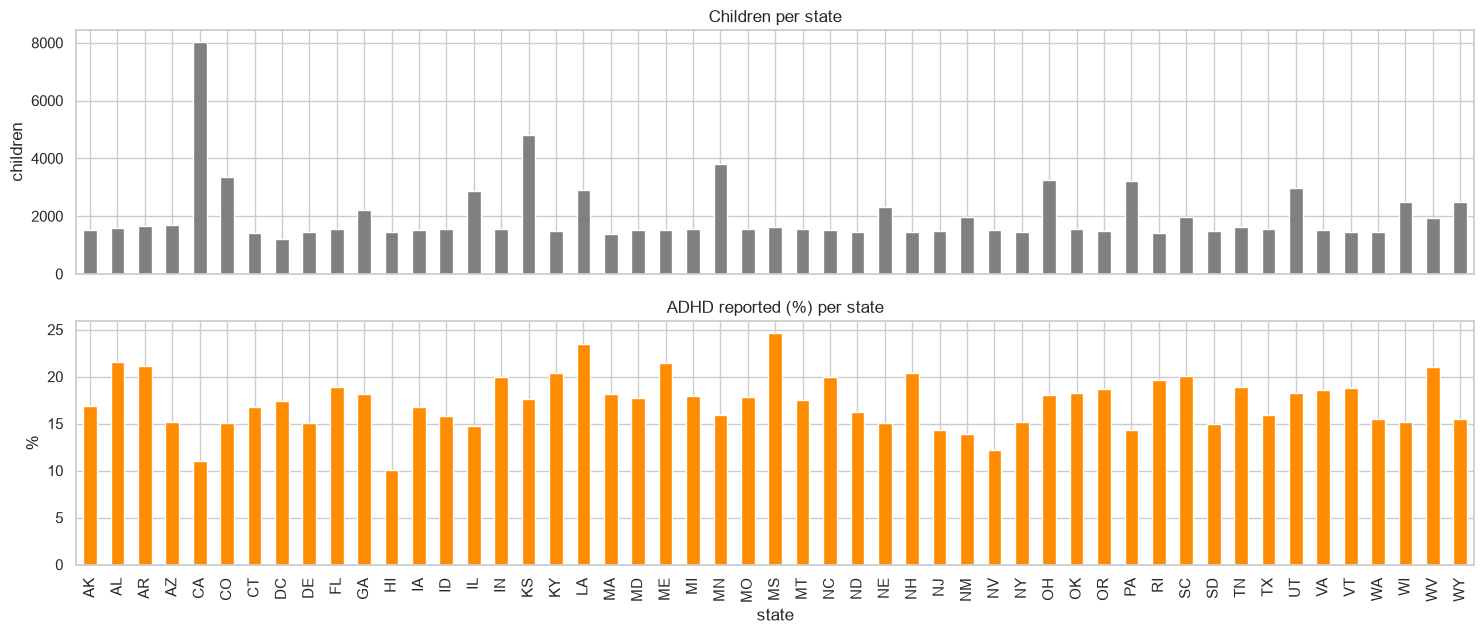

States: 51 | children per state: 1205–8025 | ADHD % per state: 10.0–24.7
ADHD in the sample: 16.9%  |  survey-weighted estimate for U.S. children 6–17: 14.3%


In [9]:
by_state = kids.groupby("state").agg(children=("adhd", "size"), adhd_pct=("adhd", "mean"))
by_state["adhd_pct"] *= 100
fig, axes = plt.subplots(2, 1, figsize=(15, 6.5), sharex=True)
by_state.children.plot.bar(ax=axes[0], color="gray"); axes[0].set_title("Children per state"); axes[0].set_ylabel("children")
by_state.adhd_pct.plot.bar(ax=axes[1], color="darkorange"); axes[1].set_title("ADHD reported (%) per state"); axes[1].set_ylabel("%")
axes[1].set_xlabel("state"); plt.tight_layout(); plt.savefig(FIG / "02_states.png", dpi=120); plt.show()
weighted = np.average(kids.adhd, weights=kids.fwc)
print(f"States: {kids.state.nunique()} | children per state: {by_state.children.min()}–{by_state.children.max()} | "
      f"ADHD % per state: {by_state.adhd_pct.min():.1f}–{by_state.adhd_pct.max():.1f}")
print(f"ADHD in the sample: {kids.adhd.mean():.1%}  |  survey-weighted estimate for U.S. children 6–17: {weighted:.1%}")

**What did we find?** Every state has several hundred children (NSCH samples each state). The share of children with ADHD varies quite a bit between states, so a model trained on some states is tested on states with a different ADHD rate. The survey-weighted estimate (using the NSCH weight `fwc`) is lower than the raw sample percentage, because the survey over-samples some groups. We train our models on the raw sample.

Look at age, the only numeric feature: a histogram split by ADHD status, and a box plot to check for outliers.

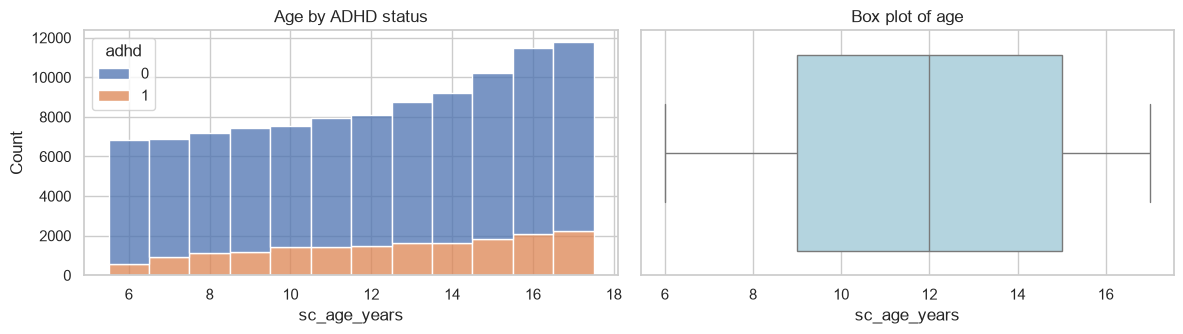

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(data=kids, x="sc_age_years", hue="adhd", discrete=True, multiple="stack", ax=axes[0]); axes[0].set_title("Age by ADHD status")
sns.boxplot(x=kids.sc_age_years, ax=axes[1], color="lightblue"); axes[1].set_title("Box plot of age")
plt.tight_layout(); plt.savefig(FIG / "03_age.png", dpi=120); plt.show()

**Outliers.** Age is the only true number among our features, and it ranges from 6 to 17, so it has **no outliers**. All the other features are answer codes (for example 1 = "always" … 4 = "never"). Box plots and the IQR rule don't make sense for codes, so we don't remove or change any values. Answers like "no valid response" are already stored as missing values. Older children are more likely to have ADHD reported, because "ever diagnosed" adds up over childhood.

## 5. Prepare the Data for Machine Learning

**What are we doing?** We build a **pipeline** that fills in missing values, turns the answer codes into 0/1 columns (one-hot encoding) and scales age.

**Why?** Putting these steps inside a scikit-learn `Pipeline` means they are learned **only from the training data** in every experiment. The test children never influence the preprocessing, so there is no data leakage.

In [11]:
def make_pipeline(features, model):
    numeric = ["sc_age_years"]                                   # the only real number
    categorical = [c for c in features if c not in numeric]      # everything else is an answer code
    prep = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), categorical)])
    return Pipeline([("prep", prep), ("model", model)])

**Class imbalance.** Only about 17 % of the children have ADHD reported, so every model uses `class_weight="balanced"`. Mistakes on ADHD children count more during training, which pushes the model to find more of them (higher recall) instead of always guessing "No".

## 6. Four Ways to Split the Data

**Method 1 – Random split (80/20).** Children are shuffled and 20 % are kept for testing, with the same ADHD rate in both parts (stratified). Every state appears in both training and testing, so this shows how well the model works on **new children from familiar states**.

**Method 2 – Geographic split.** About 20 % of the **states** are set aside, and their children are used only for testing. The model never sees anyone from those states during training or tuning.

**Method 3 – Group K-Fold (5 folds).** The 51 states are divided into 5 groups of about 10 states. The model trains on 4 groups and is tested on the 5th, and this repeats 5 times, so every state is tested once as an unseen state. It is a middle ground between one geographic split and LOSO.

**Method 4 – Leave-One-State-Out (LOSO).** Train on 50 states, test on the one left out, and repeat until every state has been the test state once. This is the strongest test of whether the model works in **unseen states**.

The next cell creates all four splits and checks that the geographic split never puts the same state on both sides.

In [12]:
# Method 1: random 80/20 split, stratified by ADHD
train_r, test_r = train_test_split(kids, test_size=0.2, stratify=kids.adhd, random_state=SEED)

# Method 2: geographic split – whole states go to the test set
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(gss.split(kids, groups=kids.state))
train_g, test_g = kids.iloc[train_idx], kids.iloc[test_idx]
assert set(train_g.state).isdisjoint(test_g.state)            # check: no state on both sides

# Method 3: Group K-Fold – 5 folds of about 10 states each
gkf = GroupKFold(n_splits=5)

# Method 4: leave-one-state-out
loso = LeaveOneGroupOut()

print(f"Random split    : {len(train_r):,} train / {len(test_r):,} test children (all 51 states in both)")
print(f"Geographic split: {train_g.state.nunique()} training states, {test_g.state.nunique()} test states: {sorted(test_g.state.unique())}")
print(f"Group K-Fold    : {gkf.get_n_splits()} folds of about 10 states each")
print(f"LOSO            : {loso.get_n_splits(groups=kids.state)} rounds, one per state")

Random split    : 82,682 train / 20,671 test children (all 51 states in both)
Geographic split: 40 training states, 11 test states: ['AZ', 'IA', 'ID', 'KY', 'MO', 'NH', 'NJ', 'NM', 'SC', 'TX', 'VT']
Group K-Fold    : 5 folds of about 10 states each
LOSO            : 51 rounds, one per state


**Which states are tested in each Group K-Fold fold?** The table lists the test states of each of the 5 folds and how many children they contain.

In [13]:
folds = []
for k, (tr, te) in enumerate(gkf.split(kids, groups=kids.state), start=1):
    test_states = sorted(kids.state.iloc[te].unique())
    folds.append({"Fold": k, "Test states": ", ".join(test_states), "Number of test states": len(test_states),
                  "Test children": len(te), "Training children": len(tr)})
pd.DataFrame(folds)

,Fold,Test states,Number of test states,Test children,Training children
0,1,"AK, CA, CT, MI, ND, OK, SC, SD, TN",9,20577,82776
1,2,"AR, GA, ID, IL, KS, KY, ME, NY, RI, TX",10,20589,82764
2,3,"AZ, LA, MA, MN, MS, MT, NC, NE, NH, NJ, NV",11,21233,82120
3,4,"AL, CO, DC, HI, MD, MO, NM, UT, VA, WA, WY",11,21041,82312
4,5,"DE, FL, IA, IN, OH, OR, PA, VT, WI, WV",10,19913,83440


**What did we find?** `GroupKFold` balances the folds by size: each fold tests 9–11 states with about 20,000 children (19,913–21,233) and trains on the other ~82,000–83,000. California, the largest state, is in fold 1. Every state is in exactly one test fold.

**How much data does each LOSO round use?** In each LOSO round one state is the test set and the other 50 states are the training set. The table shows, for every state, how many children it contributes as the test state (and how many have ADHD), and how many children the model trains on in that round.

In [14]:
loso_sizes = kids.groupby("state").agg(test_children=("adhd", "size"), adhd_children=("adhd", "sum"))
loso_sizes["training_children"] = len(kids) - loso_sizes.test_children
loso_sizes.sort_values("test_children", ascending=False)

,test_children,adhd_children,training_children
state,,,
CA,8025,887,95328
KS,4804,845,98549
MN,3792,604,99561
CO,3341,504,100012
OH,3247,586,100106
PA,3214,460,100139
UT,2974,544,100379
LA,2888,678,100465
IL,2876,425,100477


**What did we find?** A LOSO test state contributes between 1,205 children (DC) and 8,025 children (California), with 145 (Hawaii) to 887 (California) of them having ADHD reported. The model is always trained on a large set: between 95,328 and 102,148 children from the other 50 states.

## 7. Train and Tune Six Models

**What are we doing?** We train six classifiers and pick their settings (hyperparameters) with a small **grid search** and 5-fold cross-validation, using F1 as the score.

**Why?** Each model needs settings that control its complexity (to avoid overfitting). For the geographic experiments we tune with `GroupKFold`, so whole states are kept together in each validation fold, and the test states are never used to choose settings.

In [15]:
MODELS = {   # model, small grid of settings to try
    "Linear Regression": (RidgeClassifier(class_weight="balanced"), {"model__alpha": [0.1, 1, 10]}),
    "Logistic Regression": (LogisticRegression(max_iter=2000, class_weight="balanced"), {"model__C": [0.01, 0.1, 1]}),
    "Decision Tree": (DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
                      {"model__max_depth": [4, 6, 8], "model__min_samples_leaf": [50, 200]}),
    "Random Forest": (RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED),
                      {"model__max_depth": [8, 12], "model__min_samples_leaf": [10, 30]}),
    "SVM": (LinearSVC(class_weight="balanced", max_iter=5000), {"model__C": [0.01, 0.1]}),
    "Gradient Boosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
                          {"model__learning_rate": [0.05, 0.1], "model__max_depth": [3, 6]}),
}

* **Linear Regression:** fits a straight-line (least-squares) regression to the 0/1 ADHD target and predicts ADHD when the output is above the middle. A plain `LinearRegression` returns numbers, not classes, so we use scikit-learn's `RidgeClassifier`, which is exactly this least-squares linear regression used as a classifier. `alpha` adds a little regularization, like Ridge regression in the lecture.
* **Logistic Regression:** a linear model. `C` controls regularization; a smaller `C` keeps the model simpler.
* **Decision Tree:** learns yes/no rules. Depth and minimum leaf size stop it from memorizing the data.
* **Random Forest:** many trees trained on random samples, then averaged.
* **SVM (linear):** finds the boundary with the widest margin between the classes.
* **Gradient Boosting:** adds small trees one at a time, each fixing the previous errors.

The `tune` function runs a small grid search for one model and feature set. Each model is tuned twice: with normal 5-fold cross-validation on the random-split training data, and with `GroupKFold` (whole states kept together) on the geographic training states.

In [16]:
def tune(name, features, train, cv, groups=None):
    model, grid = MODELS[name]
    search = GridSearchCV(make_pipeline(features, model), grid, scoring="f1", cv=cv, n_jobs=-1, return_train_score=True)
    return search.fit(train[features], train.adhd, groups=groups)

searches = {}
for fs, feats in FEATURE_SETS.items():
    for name in MODELS:
        searches[(fs, name, "random")] = tune(name, feats, train_r, StratifiedKFold(5, shuffle=True, random_state=SEED))
        searches[(fs, name, "geographic")] = tune(name, feats, train_g, GroupKFold(5), groups=train_g.state)
    print("tuned:", fs)

tuned: 17 features


tuned: 27 features


Collect the best settings and the training vs validation F1 of every model (from the state-grouped tuning) in one table.

In [17]:
tuning = pd.DataFrame([{"Features": fs, "Model": name, "Best settings": s.best_params_,
                        "Train F1": s.cv_results_["mean_train_score"][s.best_index_], "Validation F1": s.best_score_}
                       for (fs, name, split), s in searches.items() if split == "geographic"])
tuning["Train − validation"] = tuning["Train F1"] - tuning["Validation F1"]
tuning.round(3)

,Features,Model,Best settings,Train F1,Validation F1,Train − validation
0,17 features,Linear Regression,{'model__alpha': 1},0.373,0.370,0.003
1,17 features,Logistic Regression,{'model__C': 1},0.373,0.371,0.002
2,17 features,Decision Tree,"{'model__max_depth': 8, 'model__min_samples_le...",0.369,0.355,0.014
3,17 features,Random Forest,"{'model__max_depth': 12, 'model__min_samples_l...",0.392,0.368,0.024
4,17 features,SVM,{'model__C': 0.1},0.373,0.370,0.002
5,17 features,Gradient Boosting,"{'model__learning_rate': 0.1, 'model__max_dept...",0.382,0.372,0.010
6,27 features,Linear Regression,{'model__alpha': 1},0.566,0.564,0.002
7,27 features,Logistic Regression,{'model__C': 1},0.566,0.564,0.002
8,27 features,Decision Tree,"{'model__max_depth': 6, 'model__min_samples_le...",0.544,0.540,0.004
9,27 features,Random Forest,"{'model__max_depth': 12, 'model__min_samples_l...",0.581,0.559,0.022


**Checking for overfitting.** The table compares F1 on the training folds with F1 on the validation folds (states the model did not train on). A large difference would mean the model memorizes the training data (**overfitting**).

## 8. Test the Models with All Four Split Methods

**What are we doing?** We test every tuned model with the random split, the geographic split, Group K-Fold and LOSO, and calculate accuracy, balanced accuracy, precision, recall, F1 and ROC-AUC.

**Why?** Comparing the same model under the four methods shows whether performance drops when the model has to work in unseen states.

In [18]:
def get_scores(model, X):
    # ADHD probability (or the SVM's decision score) – needed for ROC-AUC
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

def evaluate(y_true, y_pred, y_score):
    return {"Accuracy": accuracy_score(y_true, y_pred), "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred), "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred), "ROC-AUC": roc_auc_score(y_true, y_score)}

Run every model under all four split methods. For Group K-Fold and LOSO, `cross_val_predict` refits the model once per fold, so every child is predicted by a model that never saw their state.

In [19]:
def out_of_fold(model, feats, name, cv):
    # predict every child with a model trained without that child's state (used for Group K-Fold and LOSO)
    has_proba = hasattr(model, "predict_proba")                         # SVM and linear regression only give scores
    s = cross_val_predict(model, kids[feats], kids.adhd, groups=kids.state, cv=cv,
                          method="predict_proba" if has_proba else "decision_function", n_jobs=-1)
    s = s[:, 1] if has_proba else s
    return (s > (0.5 if has_proba else 0)).astype(int), s                 # same rule as model.predict()

rows, loso_pred = [], {}
for fs, feats in FEATURE_SETS.items():
    for name in MODELS:
        # Method 1 – random split
        m = searches[(fs, name, "random")].best_estimator_
        rows.append({"Features": fs, "Model": name, "Split": "Random", **evaluate(test_r.adhd, m.predict(test_r[feats]), get_scores(m, test_r[feats]))})
        # Method 2 – geographic split
        m = searches[(fs, name, "geographic")].best_estimator_
        rows.append({"Features": fs, "Model": name, "Split": "Geographic", **evaluate(test_g.adhd, m.predict(test_g[feats]), get_scores(m, test_g[feats]))})
        # Method 3 – Group K-Fold (5 folds of states), same settings as the geographic split
        pred, s = out_of_fold(m, feats, name, gkf)
        rows.append({"Features": fs, "Model": name, "Split": "Group K-Fold", **evaluate(kids.adhd, pred, s)})
        # Method 4 – LOSO, same settings
        pred, s = out_of_fold(m, feats, name, loso)
        loso_pred[(fs, name)] = (pred, s)
        rows.append({"Features": fs, "Model": name, "Split": "LOSO", **evaluate(kids.adhd, pred, s)})
    print("evaluated:", fs)
results = pd.DataFrame(rows)
results.to_csv(OUT / "results_all_models.csv", index=False)

evaluated: 17 features


evaluated: 27 features


## 9. Model Performance Comparison

### Chart 1 – Compare all models (LOSO, unseen states)
Each group of bars is one model, and the colors are the five metrics. We show the LOSO results because they test unseen states, which is our research question.

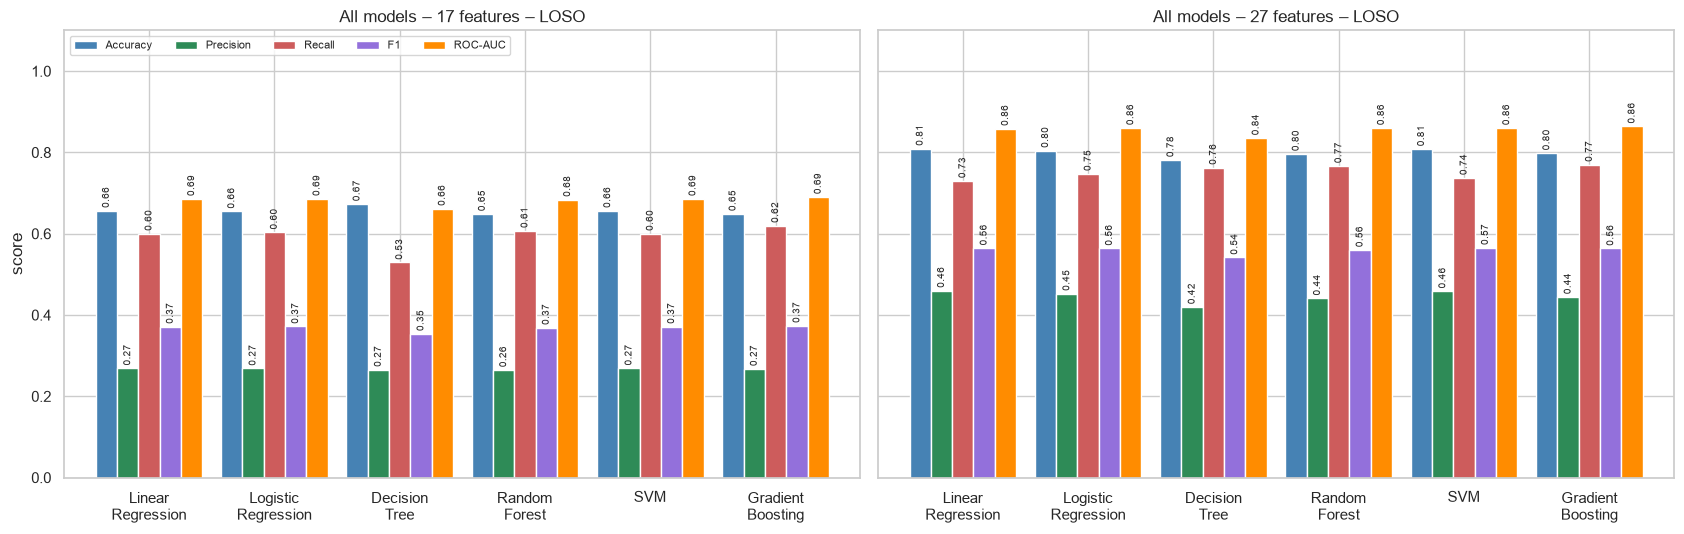

In [20]:
METRICS = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
COLORS = ["steelblue", "seagreen", "indianred", "mediumpurple", "darkorange"]
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), sharey=True)
for ax, fs in zip(axes, FEATURE_SETS):
    d = results[(results.Split == "LOSO") & (results.Features == fs)].set_index("Model")[METRICS]
    d.plot.bar(ax=ax, color=COLORS, width=0.85, rot=0, legend=(fs == "17 features"))
    ax.set_xticklabels([n.replace(" ", "\n", 1) for n in d.index])          # model names on two lines
    for bars in ax.containers: ax.bar_label(bars, fmt="%.2f", fontsize=7, rotation=90, padding=2)
    ax.set_ylim(0, 1.1); ax.set_title(f"All models – {fs} – LOSO"); ax.set_xlabel(""); ax.set_ylabel("score")
axes[0].legend(ncol=5, fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "04_chart1_all_models.png", dpi=120); plt.show()

**What did we find?** With 27 features, all six models score close together on unseen states: F1 0.54–0.57, recall 0.73–0.77 and ROC-AUC 0.84–0.86. Accuracy (about 0.78–0.81) is the tallest bar, but it is inflated by the many "No ADHD" children. Precision is the lowest bar (about 0.42–0.46): more than half of the flagged children do not have ADHD reported. That is the price of finding most ADHD cases with `class_weight="balanced"`. With 17 features every model is much weaker (F1 about 0.35–0.37, ROC-AUC about 0.66–0.69).

### Chart 2 – Compare the splitting methods (F1-score)

Each model has four bars: random split, geographic split, Group K-Fold and LOSO. If the last three bars are as tall as the first, the model works as well in unseen states as in familiar ones.

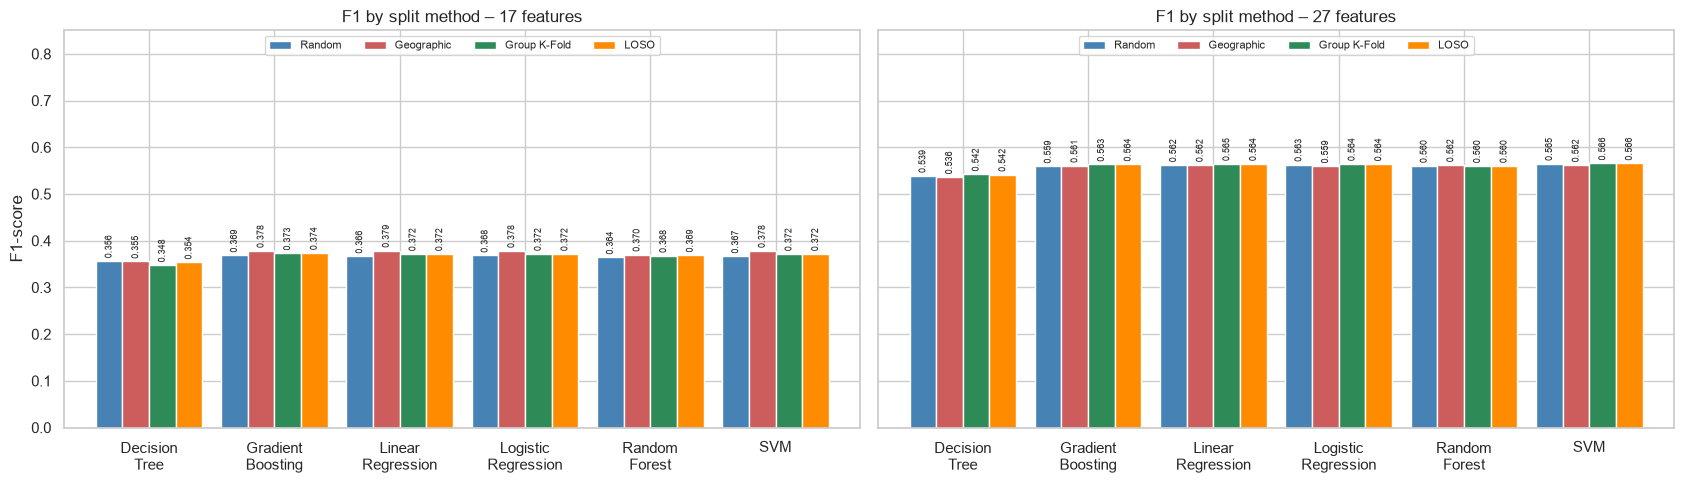

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5), sharey=True)
for ax, fs in zip(axes, FEATURE_SETS):
    d = results[results.Features == fs].pivot(index="Model", columns="Split", values="F1")[["Random", "Geographic", "Group K-Fold", "LOSO"]]
    d.plot.bar(ax=ax, color=["steelblue", "indianred", "seagreen", "darkorange"], width=0.85, rot=0)
    ax.set_xticklabels([n.replace(" ", "\n", 1) for n in d.index])
    for bars in ax.containers: ax.bar_label(bars, fmt="%.3f", fontsize=6.5, rotation=90, padding=2)
    ax.set_ylim(0, 0.85); ax.set_title(f"F1 by split method – {fs}"); ax.legend(ncol=4, loc="upper center", fontsize=8); ax.set_xlabel(""); ax.set_ylabel("F1-score")
plt.tight_layout(); plt.savefig(FIG / "05_chart2_split_methods.png", dpi=120); plt.show()

**What did we find?** F1 is practically the same under all four methods. With 27 features, the geographic split, Group K-Fold and LOSO differ from the random split by at most about 0.005 for every model. For the selected SVM, F1 is 0.565 (random), 0.562 (geographic), 0.566 (Group K-Fold) and 0.566 (LOSO). Group K-Fold and LOSO give almost identical results, because both predict every state once as an unseen state; they differ only in how many states are left out at a time (about 10 vs 1). Differences this small are just noise from which children end up in the test set. **Performance does not drop in states the model has never seen.**

### Chart 3 – 17 features vs 27 features (LOSO)

Put the 17-feature and 27-feature LOSO results side by side and plot the F1-scores.

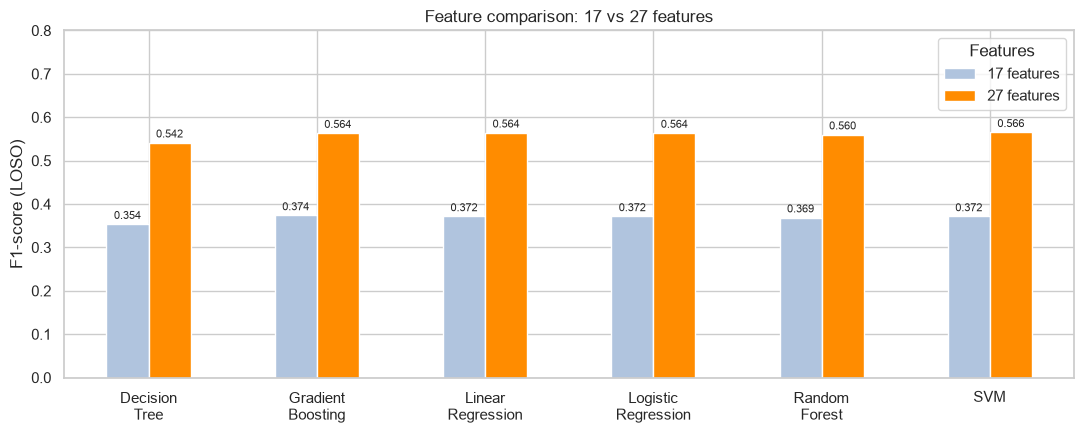

F1                  Recall              \
Features            17 features 27 features 17 features 27 features   
Model                                                                 
Decision Tree             0.354       0.542       0.529       0.763   
Gradient Boosting         0.374       0.564       0.620       0.770   
Linear Regression         0.372       0.564       0.600       0.730   
Logistic Regression       0.372       0.564       0.604       0.748   
Random Forest             0.369       0.560       0.607       0.767   
SVM                       0.372       0.566       0.600       0.738   

                        ROC-AUC              
Features            17 features 27 features  
Model                                        
Decision Tree             0.662       0.835  
Gradient Boosting         0.691       0.864  
Linear Regression         0.686       0.859  
Logistic Regression       0.686       0.860  
Random Forest             0.684       0.860  
SVM                       0.686       0.860

In [22]:
d = results[results.Split == "LOSO"].pivot(index="Model", columns="Features", values=["F1", "Recall", "ROC-AUC"])
ax = d["F1"].plot.bar(figsize=(11, 4.5), color=["lightsteelblue", "darkorange"], rot=0)
ax.set_xticklabels([n.replace(" ", "\n", 1) for n in d.index])
for bars in ax.containers: ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
ax.set_ylim(0, 0.8); ax.set_ylabel("F1-score (LOSO)"); ax.set_title("Feature comparison: 17 vs 27 features"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "06_chart3_features.png", dpi=120); plt.show()
d.round(3)

**What did we find?** Adding the 10 behaviour and health features raises LOSO F1 from about 0.37 to about 0.56, recall from about 0.60 to about 0.75, and ROC-AUC from about 0.68 to about 0.86, for **every** model. The choice of features matters much more than the choice of model. Remember, though, that some of these extra features may be recorded *after* a diagnosis (Section 3.1).

### Results table – every model, feature set and split method

Show every result (feature set × model × split method) in one table; the F1 column is shaded from low to high.

In [23]:
table = results[["Features", "Model", "Split", "Accuracy", "Balanced accuracy", "Precision", "Recall", "F1", "ROC-AUC"]]
table.round(3).style.hide(axis="index").background_gradient(subset=["F1"], cmap="Greens")

Features,Model,Split,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC
17 features,Linear Regression,Random,0.650000,0.630000,0.264000,0.599000,0.366000,0.682000
17 features,Linear Regression,Geographic,0.656000,0.639000,0.274000,0.613000,0.379000,0.688000
17 features,Linear Regression,Group K-Fold,0.657000,0.634000,0.269000,0.601000,0.372000,0.686000
17 features,Linear Regression,LOSO,0.657000,0.634000,0.269000,0.600000,0.372000,0.686000
17 features,Logistic Regression,Random,0.650000,0.632000,0.265000,0.604000,0.368000,0.682000
17 features,Logistic Regression,Geographic,0.653000,0.638000,0.273000,0.615000,0.378000,0.687000
17 features,Logistic Regression,Group K-Fold,0.655000,0.635000,0.269000,0.604000,0.372000,0.686000
17 features,Logistic Regression,LOSO,0.655000,0.635000,0.269000,0.604000,0.372000,0.686000
17 features,Decision Tree,Random,0.668000,0.619000,0.265000,0.544000,0.356000,0.666000
17 features,Decision Tree,Geographic,0.626000,0.616000,0.252000,0.601000,0.355000,0.658000


### Ranking of all models on unseen states
One row per model and feature set. **Validation F1** is the score used to choose the model (state-grouped cross-validation on the training states). The other columns are the final results on unseen states: LOSO F1, recall, balanced accuracy and ROC-AUC, plus how much F1 varies between states (a lower spread means more consistent).

In [24]:
rank = []
for (fs, name), (p, s) in loso_pred.items():
    by_state = pd.DataFrame({"adhd": kids.adhd, "pred": p, "state": kids.state}).groupby("state").apply(
        lambda g: f1_score(g.adhd, g.pred), include_groups=False)
    r = results[(results.Features == fs) & (results.Model == name) & (results.Split == "LOSO")].iloc[0]
    rank.append({"Features": fs, "Model": name, "Validation F1": searches[(fs, name, "geographic")].best_score_,
                 "LOSO F1": r["F1"], "LOSO Recall": r["Recall"], "LOSO Balanced accuracy": r["Balanced accuracy"],
                 "LOSO ROC-AUC": r["ROC-AUC"], "State F1 spread (std)": by_state.std()})
ranking = pd.DataFrame(rank).sort_values("Validation F1", ascending=False).reset_index(drop=True)
ranking.index += 1
ranking.round(3)

,Features,Model,Validation F1,LOSO F1,LOSO Recall,LOSO Balanced accuracy,LOSO ROC-AUC,State F1 spread (std)
1,27 features,SVM,0.566,0.566,0.738,0.780,0.860,0.033
2,27 features,Logistic Regression,0.564,0.564,0.748,0.782,0.860,0.034
3,27 features,Linear Regression,0.564,0.564,0.730,0.778,0.859,0.032
4,27 features,Gradient Boosting,0.563,0.564,0.770,0.787,0.864,0.035
5,27 features,Random Forest,0.559,0.560,0.767,0.785,0.860,0.036
6,27 features,Decision Tree,0.540,0.542,0.763,0.774,0.835,0.038
7,17 features,Gradient Boosting,0.372,0.374,0.620,0.637,0.691,0.036
8,17 features,Logistic Regression,0.371,0.372,0.604,0.635,0.686,0.036
9,17 features,SVM,0.370,0.372,0.600,0.634,0.686,0.036
10,17 features,Linear Regression,0.370,0.372,0.600,0.634,0.686,0.036


**What did we find?** The **SVM with 27 features** ranks first on validation F1 (0.566) and also has the best LOSO F1 (0.566), so it is our best model. But the top four 27-feature models are practically tied:

| Model (27 features) | Validation F1 | LOSO F1 |
|---|---|---|
| SVM | 0.566 | 0.566 |
| Logistic regression | 0.564 | 0.564 |
| **Linear regression** | 0.564 | 0.564 |
| Gradient boosting | 0.563 | 0.564 |

The differences are only about 0.002–0.003, and all four have nearly the same spread across states (standard deviation 0.032–0.035). Gradient boosting finds slightly more ADHD cases (recall 0.77 vs 0.74), but with more false alarms. Random forest and especially the decision tree are a little weaker. Every 17-feature model is far behind (F1 about 0.35–0.37). In short, the **choice of features** matters much more than the choice of model, and a simple linear model is enough.

## 10. Select the Best Model

**What are we doing?** We pick the model with the best **validation** F1 from the geographic tuning (state-grouped cross-validation on the training states).

**Why?** Choosing a model by looking at the test results would make those results look better than they really are. The validation score was computed before we looked at any test state.

In [25]:
validation = tuning.sort_values("Validation F1", ascending=False)[["Features", "Model", "Validation F1"]]
display(validation.round(4))
best = validation.iloc[0]
BEST_FS, BEST_MODEL = best["Features"], best["Model"]
print(f"Selected model: {BEST_MODEL} with {BEST_FS} (validation F1 = {best['Validation F1']:.3f})")
results[(results.Model == BEST_MODEL) & (results.Features == BEST_FS)].round(3)

,Features,Model,Validation F1
10,27 features,SVM,0.5658
7,27 features,Logistic Regression,0.5638
6,27 features,Linear Regression,0.5636
11,27 features,Gradient Boosting,0.5632
9,27 features,Random Forest,0.5585
8,27 features,Decision Tree,0.5400
5,17 features,Gradient Boosting,0.3721
1,17 features,Logistic Regression,0.3710
4,17 features,SVM,0.3704
0,17 features,Linear Regression,0.3701


Selected model: SVM with 27 features (validation F1 = 0.566)


,Features,Model,Split,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC
40,27 features,SVM,Random,0.808,0.779,0.459,0.736,0.565,0.856
41,27 features,SVM,Geographic,0.801,0.778,0.452,0.743,0.562,0.861
42,27 features,SVM,Group K-Fold,0.809,0.780,0.459,0.738,0.566,0.860
43,27 features,SVM,LOSO,0.808,0.780,0.459,0.738,0.566,0.860


Confusion matrix of the selected model's LOSO predictions: how many children were correctly and wrongly classified.

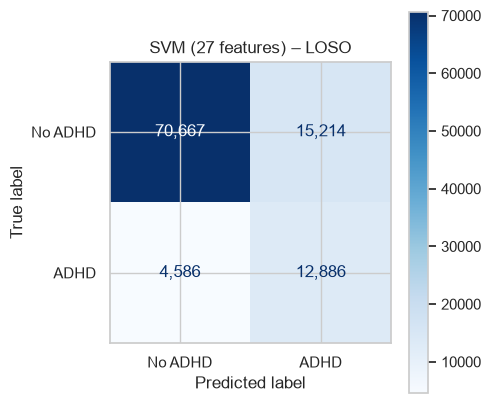

In [26]:
pred, score = loso_pred[(BEST_FS, BEST_MODEL)]
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(kids.adhd, pred), display_labels=["No ADHD", "ADHD"]).plot(ax=ax, cmap="Blues", values_format=",")
ax.set_title(f"{BEST_MODEL} ({BEST_FS}) – LOSO"); plt.tight_layout(); plt.savefig(FIG / "07_confusion_matrix.png", dpi=120); plt.show()

**What did we find?** Under LOSO, every child was predicted by a model that never saw their state. The selected model finds about **74 %** of the children with ADHD reported (recall 0.74). But only about **46 %** of the children it flags actually have ADHD reported (precision 0.46), and it wrongly flags roughly one in six children without ADHD. It is good at finding cases, but it produces many false alarms.

Calculate the selected model's F1 and recall separately for each state when that state was left out (LOSO), and plot them from lowest to highest.

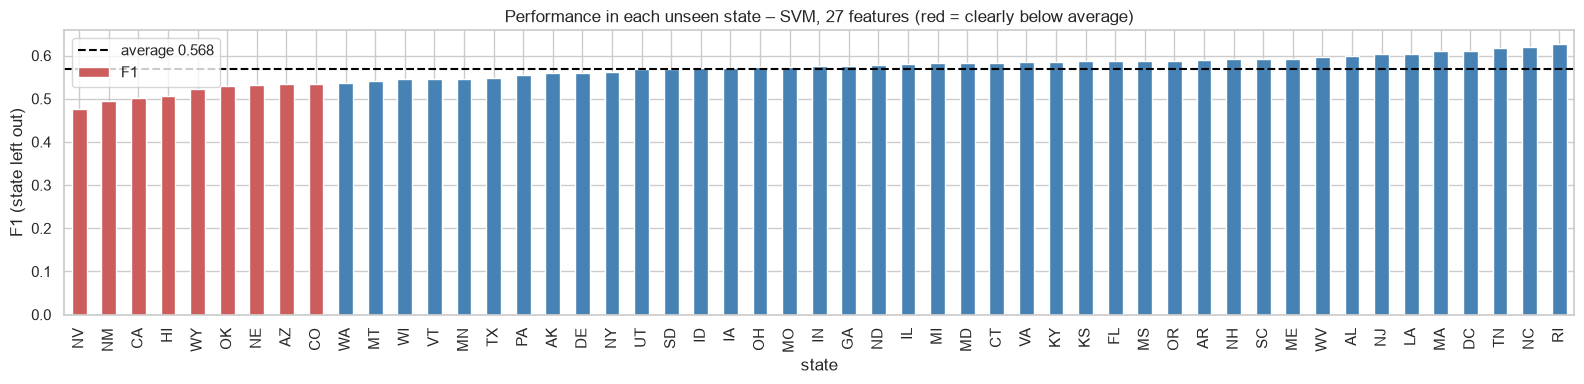

State F1: mean 0.568, std 0.033, lowest: {'NV': 0.477, 'NM': 0.494, 'CA': 0.501, 'HI': 0.507, 'WY': 0.522}


In [27]:
per_state = pd.DataFrame({"adhd": kids.adhd, "pred": pred, "state": kids.state}).groupby("state").apply(
    lambda g: pd.Series({"children": len(g), "ADHD %": 100 * g.adhd.mean(), "F1": f1_score(g.adhd, g.pred),
                         "Recall": recall_score(g.adhd, g.pred)}), include_groups=False).sort_values("F1")
ax = per_state.F1.plot.bar(figsize=(16, 4), color=np.where(per_state.F1 < per_state.F1.mean() - per_state.F1.std(), "indianred", "steelblue"))
ax.axhline(per_state.F1.mean(), color="black", ls="--", label=f"average {per_state.F1.mean():.3f}")
ax.set_ylabel("F1 (state left out)"); ax.set_title(f"Performance in each unseen state – {BEST_MODEL}, {BEST_FS} (red = clearly below average)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "08_performance_by_state.png", dpi=120); plt.show()
per_state.to_csv(OUT / "state_results_best_model.csv")
print(f"State F1: mean {per_state.F1.mean():.3f}, std {per_state.F1.std():.3f}, lowest: {per_state.F1.head(5).round(3).to_dict()}")

**What did we find?** The average state F1 is 0.57, with a small spread (standard deviation 0.033). The lowest states are Nevada (0.48), New Mexico (0.49), California (0.50), Hawaii (0.51) and Wyoming (0.52); the highest are Rhode Island (0.63), North Carolina and Tennessee (0.62). Most of the lowest states have a low ADHD rate (Hawaii 10 %, California 11 %, Nevada 12 %, New Mexico 14 %), and F1 is naturally lower when the positive class is rarer. Recall stays between 0.72 and 0.79 in these five states.

## 11. What Does the Best Model Pay Attention To? (SHAP)

**What are we doing?** We use SHAP to measure how much each feature pushes the model's predictions up or down, and add up the 0/1 columns of each survey question.

**Why?** It helps us understand and trust the model. SHAP explains the **model**; it does not prove that a feature causes ADHD.

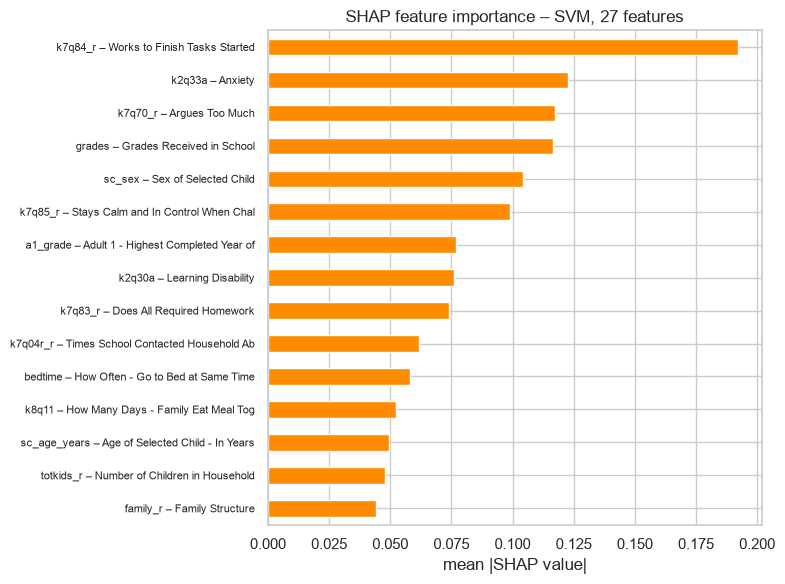

In [28]:
pipe = searches[(BEST_FS, BEST_MODEL, "geographic")].best_estimator_       # trained on the geographic training states
feats = FEATURE_SETS[BEST_FS]
sample = test_g.sample(1000, random_state=SEED)                            # children from unseen test states
X_enc = pd.DataFrame(pipe["prep"].transform(sample[feats]), columns=pipe["prep"].get_feature_names_out())

if BEST_MODEL in ("Gradient Boosting", "Random Forest", "Decision Tree"):
    explainer = shap.TreeExplainer(pipe["model"])
else:
    explainer = shap.LinearExplainer(pipe["model"], X_enc.iloc[:100])        # 100 children as the reference background
values = explainer(X_enc).values
values = values[:, :, 1] if values.ndim == 3 else values                   # trees with 2 outputs: keep the ADHD class

# add up the one-hot columns that belong to the same survey question
question = [next(f for f in sorted(feats, key=len, reverse=True) if c.split("__")[1].startswith(f)) for c in X_enc.columns]
importance = pd.Series(np.abs(values).mean(axis=0), index=question).groupby(level=0).sum().sort_values()
ax = importance.tail(15).plot.barh(figsize=(8, 6), color="darkorange")
ax.set_yticklabels([f"{c} – {DESC.get(c, '')[:35]}" for c in importance.tail(15).index], fontsize=8)
ax.set_xlabel("mean |SHAP value|"); ax.set_title(f"SHAP feature importance – {BEST_MODEL}, {BEST_FS}")
plt.tight_layout(); plt.savefig(FIG / "09_shap_importance.png", dpi=120); plt.show()

**What did we find?** The model relies most on whether the child **finishes tasks they start**, **anxiety**, **arguing**, **school grades** and **sex**, followed by staying calm, the parent's education and learning disability. Behaviour and school features dominate; family and lifestyle features such as bedtime and family meals matter less. These are associations the model uses, **not causes**, and some of them (school problems, other diagnoses) can happen *because of* ADHD.

## 12. Fairness Check (race and ethnicity were not model inputs)

Compare the selected model's recall, precision and F1 across race and ethnicity groups. These columns were never model inputs.

In [29]:
fair = kids.assign(pred=pred)
race_names = {1: "White", 2: "Black", 3: "American Indian/Alaska Native", 4: "Asian", 5: "Native Hawaiian/Pacific Islander", 7: "Two or more races"}
fair["group"] = fair.sc_race_r.map(race_names).where(fair.sc_hispanic_r != 1, "Hispanic (any race)")
fair.groupby("group").apply(lambda g: pd.Series({"children": len(g), "ADHD %": 100 * g.adhd.mean(),
                                                "Recall": recall_score(g.adhd, g.pred), "Precision": precision_score(g.adhd, g.pred),
                                                "F1": f1_score(g.adhd, g.pred)}), include_groups=False).round(3)

,children,ADHD %,Recall,Precision,F1
group,,,,,
American Indian/Alaska Native,595.0,17.815,0.811,0.475,0.599
Asian,6317.0,5.351,0.704,0.317,0.438
Black,6274.0,16.624,0.749,0.454,0.565
Hispanic (any race),14873.0,13.367,0.763,0.387,0.513
Native Hawaiian/Pacific Islander,233.0,6.438,0.667,0.256,0.370
Two or more races,7119.0,18.121,0.761,0.469,0.580
White,67942.0,18.681,0.731,0.478,0.578


**What did we find?** Recall is similar for the larger groups (about 0.71–0.76 for White, Black, Hispanic, Asian and multiracial children), so the model finds a similar share of ADHD cases across groups even though race and ethnicity are not inputs. Precision is lower for Asian (0.33) and Hispanic (0.39) children, groups where reported ADHD is less common (5 % and 13 %), so more of their flags are false alarms. The Native Hawaiian/Pacific Islander group is very small (233 children, about 15 with ADHD), so its numbers are not reliable.

Retrain the selected model on all children and save it, together with the results tables and charts, in `output/nsch_project/`.

In [30]:
# Save the selected model, trained on all states, for later use
final_model = searches[(BEST_FS, BEST_MODEL, "geographic")].best_estimator_
final_model.fit(kids[FEATURE_SETS[BEST_FS]], kids.adhd)
joblib.dump(final_model, OUT / "best_model.joblib")
print("Saved:", sorted(p.name for p in OUT.iterdir()))

Saved: ['best_model.joblib', 'figures', 'results_all_models.csv', 'state_results_best_model.csv']


## 13. Answers to the Model-Selection Questions

* **Which model performed best?** Out of all six models, the **linear SVM with 27 features** had the highest validation F1 (0.566) and the highest LOSO F1 (0.566). Logistic regression (0.564), linear regression (0.564) and gradient boosting (0.563) were practically tied; logistic and linear regression are the easiest to interpret.
* **Why was it selected?** It had the best F1 in state-grouped cross-validation on the training states, which we chose *before* looking at the test states. It is also simple and fast, and it barely overfits.
* **Did it work on unseen states?** Yes. Under LOSO it reached F1 0.566, recall 0.738, balanced accuracy 0.780 and ROC-AUC 0.860, the same as on the random split (F1 0.565, ROC-AUC 0.856). With Group K-Fold (about 10 unseen states per fold), F1 was also 0.566; on the 11 geographic test states it was 0.562.
* **Did 27 features beat 17?** Yes, by a lot: LOSO F1 rose from 0.372 to 0.566 for the SVM, and the improvement was similar for every model.
* **Which states were lower?** Nevada, New Mexico, California, Hawaii and Wyoming (F1 about 0.48–0.52), most of them states with a low ADHD rate.
* **Did the model overfit?** No. For the SVM, training and validation F1 differ by only 0.002; the largest difference among all models is 0.024 (random forest).
* **What did SHAP find?** Finishing tasks, anxiety, arguing, grades and sex were the most influential features, followed by staying calm, the parent's education and learning disability.

## 14. Results, Improvements, and Conclusion

* **A better dataset for this question.** Compared with ADHD-200 (about 973 children from 9 research sites), NSCH 2023–2025 gave us about 103,000 school-age children (151,676 survey records) from all 51 state-level areas. That let us test geographic generalization on 51 unseen "sites" instead of 9.
* **Models.** We compared six models: linear regression, logistic regression, decision tree, random forest, SVM and gradient boosting. All of them performed similarly, and the gap between the best and worst model was small compared with the effect of the features. Simple linear models (linear regression, logistic regression, linear SVM) did as well as random forest and gradient boosting.
* **Behavioural features.** Adding the 10 behaviour and health features raised F1 from about 0.37 to about 0.56 and ROC-AUC from about 0.68 to about 0.86. However, these features may partly reflect problems that come *after* a diagnosis, so the 27-feature model partly recognises existing cases rather than predicting early.
* **Random vs geographic vs Group K-Fold vs LOSO.** F1 changed by at most about 0.005 when moving from the random split to completely unseen states, whether one state (LOSO), about ten states (Group K-Fold) or a fixed set of 11 states (geographic split) was held out. Our hypothesis that performance would fall in new states was **not supported**.
* **Selected model.** The linear SVM with 27 features, chosen by validation F1 (logistic regression and gradient boosting were almost tied).
* **Generalization.** Yes, within the limits of this survey: the model kept similar F1, recall and ROC-AUC in every held-out state (state F1 0.48–0.63), with lower F1 mostly in states where ADHD is reported less often.
* **Limitations.**
  * The label is a **parent's report** of a past diagnosis, not a clinical assessment.
  * Survey data can be biased (who answers, how parents remember and report).
  * The data are cross-sectional.
  * Reported ADHD was slightly lower in 2023 than in 2024–2025, so pooled years mix small changes over time.
  * Precision is under 50 %, so the model is **not a screening or diagnostic tool**.
* **Simpler than the full analysis.** This notebook uses each model's standard 0.5 decision threshold. The full analysis notebook tunes the threshold on validation data, which raises F1 somewhat, with the same overall conclusions.